# Scene-level detection comparison figure

Find a representative test-set LSST scene where match counts strictly
improve pipeline-to-pipeline (LSST Pipelines < Rubin30k <= RubinUps <
Combined), then render the paper figure + a Roman companion figure.

In [27]:
%matplotlib inline

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
from pathlib import Path

from astropy.visualization import make_lupton_rgb
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord

import astropy.units as u
from astropy.wcs.utils import proj_plane_pixel_scales
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

import os, sys
sys.path.insert(0, os.path.abspath('..'))  # repo root, for the analysis modules
import blend_metrics as bm
from plot_binned_metrics import RUN_COLORS, LSST_COLOR
from PIL import Image

root = Path('~/lsst_runs').expanduser()
all_wcs = pd.read_csv('/u/yse2/test8k_fns_wcs.csv').set_index('file_name')
out_dir = Path('paper_plots')
out_dir.mkdir(parents=True, exist_ok=True)

mag_limit_val = bm.MAG_LIMITS['gold'] + 2  # buffer=2, matches the convention used elsewhere in this notebook
GOLD_CUT = bm.MAG_LIMITS['gold']  # 25.3; the buffer band (up to mag_limit_val) exists only to keep FoF/matching
# correct near the edge (see blend_metrics.py) -- the headline metrics/sample are always mag_i < GOLD_CUT.
NARC = 10  # scalebar length, arcsec

# Canonical "Paper Runs" trio (metrics.ipynb) + the LSST-pipeline source run.
# lsst5_30k_4h200_bs192_ep50 supplies both the LSST-pipeline catalog (prefix='lsst')
# and the Rubin30k DeepDISC combo (prefix='dd') -- same run directory, two catalog types.
lsst_source_run = 'lsst5_30k_4h200_bs192_ep50'
PIPELINES = ['LSST', 'Rubin30k', 'RubinUps', 'Combined']
RUNS = {
    'LSST':     dict(prefix='lsst', run=lsst_source_run, combo=None),
    'Rubin30k': dict(prefix='dd', run='lsst5_30k_4h200_bs192_ep50', combo='s0.5_n0.6'),
    'RubinUps': dict(prefix='dd', run='lsst5_ups_30k_4h200_bs192_ep50', combo='s0.6_n0.65'),
    'Combined': dict(prefix='dd', run='comb_30k_4h200_bs144_ep50', combo='s0.6_n0.7'),
}

def scalebar_npix(w, arcsec=NARC):
    """Pixel length of `arcsec` under WCS `w`, from that scene's own pixel
    scale rather than a hardcoded LSST/Roman constant (pixel scale is
    per-tile via the WCS, and the two instruments differ ~3.5x -- see
    blend_viz_README.md)."""
    scale_deg = proj_plane_pixel_scales(w).mean()
    return int(round(arcsec / (scale_deg * 3600)))

Before we select a scene, let's take a look at the histogram of the number of truth objects per cutout.

In [28]:
LEAN_TRUTH_FLAGS = ['is_matched', 'is_sig_blend', 'is_part_of_blend', 'is_resolved_blend']
PLOT_COLS = ['file_name', 'ra', 'dec', 'mag_i']  # ra/dec for WCS projection; mag_i for the gold_only split

def load_catalogs(ll, mag_limit_val, lean=False, columns=None, extra_det_cols=None):
    """{label: {truths, dets, prefix}} for the 4 pipelines at one linking length.

    lean=True: trim truths to file_name/id/mag_i/LEAN_TRUTH_FLAGS (for the
    scene search below -- scene_table()/blend_gain_table()/gain_table()
    only need those; mag_i is what lets ordered_candidates(...,
    gold_only=True) restrict the search to the gold sample) and dets to
    file_name/mag_i.
    columns=PLOT_COLS: trim both truths and dets to file_name/ra/dec/mag_i
    (for final plotting -- draw_markers projects everything through ra/dec +
    WCS by default, see make_xy_fn's docstring, and mag_i drives the
    optional gold_only split, so nothing else is needed there either).
    extra_det_cols={label: [colnames]}: keep additional raw columns on just
    that label's dets frame (columns not already in `columns`, and only
    ones that actually exist on that catalog -- silently skipped otherwise).
    Used for Rubin30k's kp_x/kp_y (see draw_markers' native_kp_pipelines):
    those columns only exist on `dd_det` rows, so they can't go in the
    universal `columns` list without breaking the LSST truth/det load.
    Either trim drops the full ~100-col dataframe immediately, in particular
    the heavy per-object array columns (segmentation/bbox/keypoints/
    rle_masks) that made loading all 4 catalogs' full columns at once
    (~690k rows each) crash a kernel on memory -- neither the search nor the
    final plots ever touch those columns, so there's no reason to hold them.
    """
    out = {}
    for label, cfg in RUNS.items():
        df = bm.load_analysis_df(root / cfg['run'], cfg['prefix'], ll, cfg['combo'], mag_limit_val)
        t, d = bm.split_truth_det(df, cfg['prefix'])
        if lean:
            p = cfg['prefix']
            t = t[['file_name', 'id', 'mag_i'] + [f'{p}_{f}' for f in LEAN_TRUTH_FLAGS]].copy()
            d = d[['file_name', 'mag_i']].copy()
            del df
        elif columns is not None:
            t = t[columns].copy()
            det_cols = list(columns)
            if extra_det_cols and label in extra_det_cols:
                det_cols += [c for c in extra_det_cols[label] if c in d.columns and c not in det_cols]
            d = d[det_cols].copy()
            del df
        out[label] = dict(truths=t, dets=d, prefix=cfg['prefix'])
    return out

In [29]:
def truth_table(catalogs, gold_only=False):
    """Per-file_name n_truth: total truth-object count per scene, after
    restricting truths to mag_i < GOLD_CUT when gold_only=True (else the
    full gold+buffer population as loaded). Computed once from LSST's
    truths and recorded as its own step, since the truth population --
    which objects exist, and each one's own mag_i -- is shared across all
    four pipelines; the other three pipelines' truths
    frames are only consulted below for their own is_matched flag, not for
    n_truth itself.

    Also includes n_match_{label} per pipeline: that pipeline's own count
    of matched truth objects, with the same mag_i < GOLD_CUT restriction
    applied first when gold_only=True. No detection counts here -- use
    scene_table for n_det_*."""
    lsst_truths = catalogs['LSST']['truths']
    if gold_only:
        lsst_truths = lsst_truths[lsst_truths['mag_i'] < GOLD_CUT]
    frames = [lsst_truths.groupby('file_name').size().rename('n_truth')]

    for label, c in catalogs.items():
        t, p = c['truths'], c['prefix']
        if gold_only:
            t = t[t['mag_i'] < GOLD_CUT]
        n_match = t[t[f'{p}_is_matched']].groupby('file_name').size().rename(f'n_match_{label}')
        frames.append(n_match)

    return pd.concat(frames, axis=1).fillna(0)

In [30]:
# lls = ['0.5', '1.0']
# lls = ['1.0']
# cats = {'0.5': None, '1.0': None}
cats = {'1.0': None}
for ll in cats.keys():
    print(f'Loading catalogs for linking length {ll}...')
    cats[ll] = load_catalogs(ll, mag_limit_val, lean=True)

ll = list(cats.keys())[0]  # '1.0'
tt = truth_table(cats[ll], gold_only=False)

Loading catalogs for linking length 1.0...


LL=1.0": min=28, mean=54.8, n_truth<=40: 424 of 8571


39224

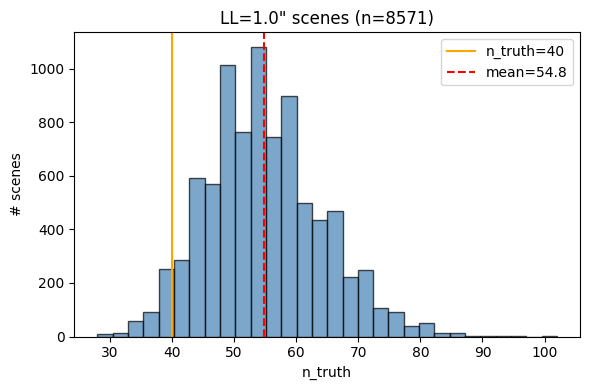

In [31]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(tt['n_truth'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_title(f'LL={ll}" scenes (n={len(tt)})')
ax.set_xlabel('n_truth')
ax.set_ylabel('# scenes')
ax.axvline(40, color='orange', label='n_truth=40')
ax.axvline(tt['n_truth'].mean(), color='red', linestyle='--', label=f'mean={tt["n_truth"].mean():.1f}')
ax.legend()
plt.tight_layout()
print(f'LL={ll}": min={tt["n_truth"].min():.0f}, mean={tt["n_truth"].mean():.1f}, n_truth<=40: {(tt["n_truth"]<=40).sum()} of {len(tt)}')
gc.collect()

Great! So as we can see, we have an average of ~55 objects per scene. This is far too many to plot as it will be really cluttered. So, let's cut the number of potential scenes to ones that have 40 objects or less. Next, out of these scenes, let's look at a distribution of the number of matches per pipeline.

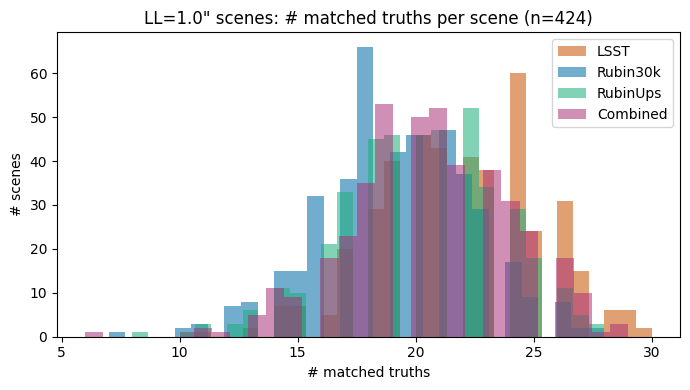

In [32]:
tt = tt[tt['n_truth'] <= 40]
fig, ax = plt.subplots(figsize=(7, 4))
colors = {'LSST': LSST_COLOR,
          'Rubin30k': RUN_COLORS[0],
          'RubinUps': RUN_COLORS[1],
          'Combined': RUN_COLORS[2]}
for p in PIPELINES:
    ax.hist(tt[f'n_match_{p}'], bins=30, alpha=0.55, label=p, color=colors[p])
ax.set_title(f'LL={ll}" scenes: # matched truths per scene (n={len(tt)})')
ax.set_xlabel('# matched truths')
ax.set_ylabel('# scenes')
ax.legend()
plt.tight_layout()

In [33]:
# Let's also get rid of scenes where LSST has more matches than all DeepDISC runs
n_lsst = tt['n_match_LSST']
outmatch = (n_lsst > tt['n_match_Rubin30k']) & \
           (n_lsst > tt['n_match_RubinUps']) & \
           (n_lsst > tt['n_match_Combined'])
print(f'LSST out-matches every DeepDISC run in {outmatch.sum()} of {len(tt)} scenes')
tt = tt[~outmatch]
tt

LSST out-matches every DeepDISC run in 220 of 424 scenes


,n_truth,n_match_LSST,n_match_Rubin30k,n_match_RubinUps,n_match_Combined
file_name,,,,,
/u/yse2/lsst_data/truth/51.04_-40.0/c221_51.04_-40.0.npy,31,20,18,19,21
/u/yse2/lsst_data/truth/51.04_-41.5/c217_51.04_-41.5.npy,37,18,19,20,17
/u/yse2/lsst_data/truth/51.05_-40.9/c49_51.05_-40.9.npy,39,24,24,24,26
/u/yse2/lsst_data/truth/51.06_-38.3/c52_51.06_-38.3.npy,33,17,14,15,17
/u/yse2/lsst_data/truth/51.06_-40.3/c196_51.06_-40.3.npy,38,19,15,18,19
...,...,...,...,...,...
/u/yse2/lsst_data/truth/54.40_-39.5/c78_54.40_-39.5.npy,37,22,21,23,23
/u/yse2/lsst_data/truth/54.42_-41.8/c211_54.42_-41.8.npy,32,17,18,18,18
/u/yse2/lsst_data/truth/54.43_-39.8/c180_54.43_-39.8.npy,39,19,19,21,19


In [34]:
# Order scenes by per-pipeline raw match counts
ordered = (tt['n_match_LSST'] <= tt['n_match_Rubin30k']) & \
          (tt['n_match_Rubin30k'] < tt['n_match_RubinUps']) & \
          (tt['n_match_RubinUps'] < tt['n_match_Combined'])
print(f'ordered LSST<=Rubin30k<RubinUps<Combined by match count: {ordered.sum()} of {len(tt)} scenes')
tt = tt[ordered]
tt = tt.sort_values('n_truth')
tt

ordered LSST<=Rubin30k<RubinUps<Combined by match count: 5 of 204 scenes


,n_truth,n_match_LSST,n_match_Rubin30k,n_match_RubinUps,n_match_Combined
file_name,,,,,
/u/yse2/lsst_data/truth/51.57_-41.8/c140_51.57_-41.8.npy,32,20,20,21,22
/u/yse2/lsst_data/truth/52.73_-40.5/c157_52.73_-40.5.npy,34,20,21,22,25
/u/yse2/lsst_data/truth/52.99_-38.5/c168_52.99_-38.5.npy,37,17,18,19,20
/u/yse2/lsst_data/truth/53.71_-41.5/c110_53.71_-41.5.npy,38,22,22,24,25
/u/yse2/lsst_data/truth/52.85_-41.9/c125_52.85_-41.9.npy,40,18,20,21,22


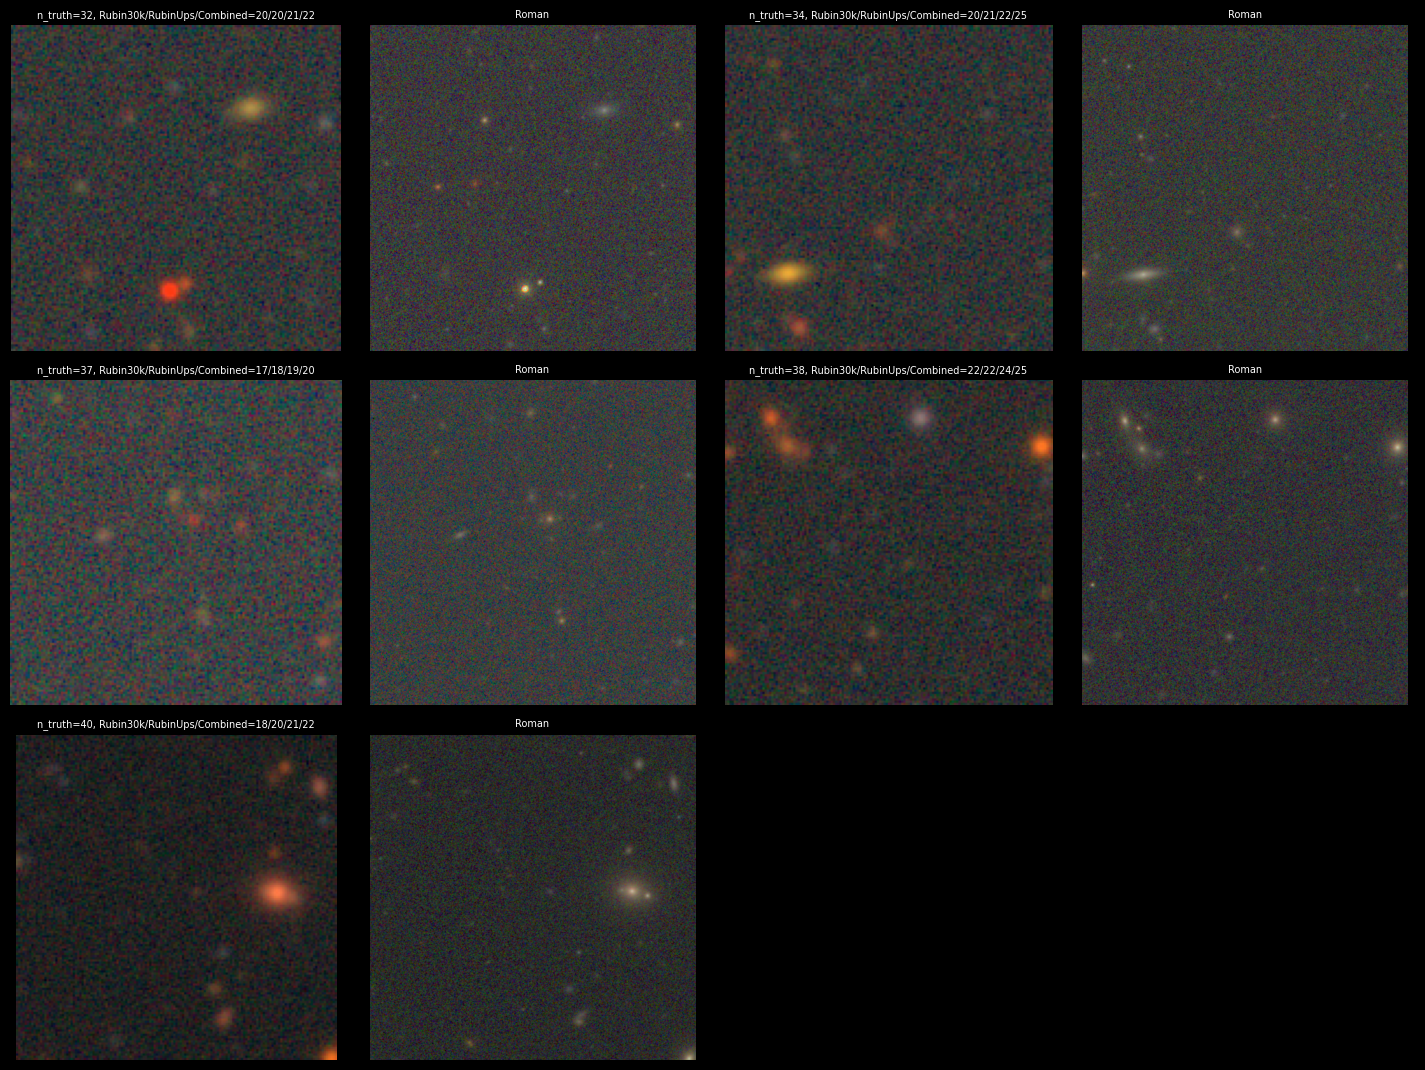

In [35]:
def make_rgb(img, bands, Q=8):
    """Per-image percentile stretch -- see blend_viz_README.md. bands=(R_idx, G_idx, B_idx)."""
    r, g, b = img[bands[0]], img[bands[1]], img[bands[2]]
    pmin = np.percentile([r, g, b], 1)
    stretch = np.percentile([r, g, b], 99.5) - pmin
    return make_lupton_rgb(r, g, b, minimum=pmin, stretch=stretch, Q=Q)

def preview_grid(cand, n=5, cands_per_row=2):
    """LSST | Roman thumbnail pairs for the top n candidates, so scenes with
    lots of *visual* blends (sources merged at LSST resolution but separable
    at Roman's finer scale) are easy to spot before picking chosen_fn/chosen_ll."""
    rows = cand.head(n)
    ncols = cands_per_row * 2  # LSST + Roman per candidate
    nrows = int(np.ceil(len(rows) / cands_per_row))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows), facecolor='black')
    axes = np.atleast_2d(axes)
    for i, (fn, row) in enumerate(rows.iterrows()):
        r, c = divmod(i, cands_per_row)
        ax_lsst, ax_roman = axes[r, 2 * c], axes[r, 2 * c + 1]

        img = np.load(fn)
        ax_lsst.imshow(make_rgb(img, bands=(3, 2, 1)), origin='lower')
        roman_img = np.load(fn.replace('lsst_data', 'roman_data'))
        ax_roman.imshow(make_rgb(roman_img, bands=(2, 1, 0), Q=10), origin='lower')

        title = f"n_truth={int(row.n_truth)}" \
                f", {PIPELINES[1]}/{PIPELINES[2]}/{PIPELINES[3]}=" \
                f"{int(row.n_match_LSST)}/{int(row.n_match_Rubin30k)}/{int(row.n_match_RubinUps)}/{int(row.n_match_Combined)}"
        ax_lsst.set_title(title, color='white', fontsize=7)
        ax_roman.set_title('Roman', color='white', fontsize=7)
        ax_lsst.axis('off')
        ax_roman.axis('off')
    for j in range(len(rows), nrows * cands_per_row):
        r, c = divmod(j, cands_per_row)
        axes[r, 2 * c].axis('off')
        axes[r, 2 * c + 1].axis('off')
    plt.tight_layout()
preview_grid(tt)

## Pick a scene

Set `chosen_fn`/`chosen_ll` from one of the shortlists above, then run the
cells below.

In [36]:
# --- fill these in after reviewing the shortlists above ---
chosen_ll = '1.0'
# chosen_fn = '/u/yse2/lsst_data/truth/52.54_-41.5/c221_52.54_-41.5.npy' # gold sample + buffer (good for overlap cutout in data section)
# chosen_fn = '/u/yse2/lsst_data/truth/53.23_-40.5/c8_53.23_-40.5.npy'

chosen_fn = '/u/yse2/lsst_data/truth/53.71_-41.5/c110_53.71_-41.5.npy'
# chosen_fn = '/u/yse2/lsst_data/truth/52.73_-40.5/c157_52.73_-40.5.npy'
# chosen_fn = '/u/yse2/lsst_data/truth/52.99_-38.5/c168_52.99_-38.5.npy'

# extra_det_cols pulls in Rubin30k's kp_x/kp_y alongside PLOT_COLS -- see
# draw_markers' native_kp_pipelines/make_xy_fn's docstring: Rubin30k's
# kp_x/kp_y already sit in this LSST cutout's native pixel frame, so
# plot_scene_dets uses them directly instead of the ra/dec->WCS
catalogs = load_catalogs(chosen_ll, mag_limit_val, columns=PLOT_COLS,
                          extra_det_cols={'Rubin30k': ['kp_x', 'kp_y']})

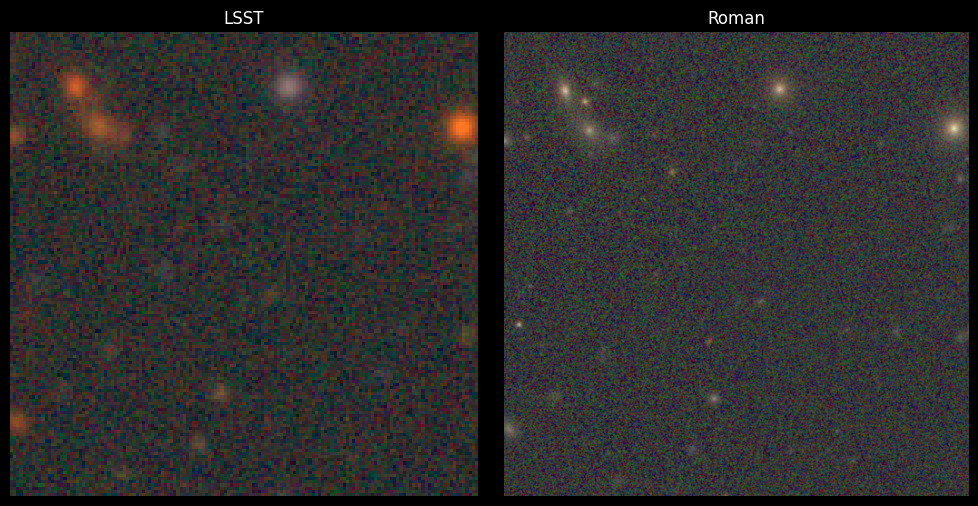

In [37]:
def plot_bare_scene(fn, figsize=(10, 5), black_bg=False):
    """Quick look at chosen_fn before the marker-heavy figures below -- just
    the LSST and Roman RGB composites side by side, no truth/detection
    overlays. black_bg=True matches the dark theme used for the candidate
    preview grids (preview_grid's facecolor='black') instead of the default
    white figure background."""
    img = np.load(fn)
    roman_img = np.load(fn.replace('lsst_data', 'roman_data'))
    fig, (ax_lsst, ax_roman) = plt.subplots(1, 2, figsize=figsize,
                                             facecolor='black' if black_bg else 'white')
    title_color = 'white' if black_bg else 'black'
    for ax, im, bands, title in ((ax_lsst, img, (3, 2, 1), 'LSST'),
                                  (ax_roman, roman_img, (2, 1, 0), 'Roman')):
        if black_bg:
            ax.set_facecolor('black')
        ax.imshow(make_rgb(im, bands=bands), origin='lower')
        ax.set_title(title, color=title_color)
        ax.axis('off')
    plt.tight_layout()

plot_bare_scene(chosen_fn, black_bg=True)

In [38]:
# Marker/shadow convention ported from visualize_unrec_blends.ipynb's
# GT_STYLE/LSST_STYLE/DD_BASE_STYLE/DD_UPS_STYLE/DD_COMB_STYLE, then tuned
# by eye against the actual chosen scene (see scene_plots_README.md for the
# full history): distinct shapes per pipeline (o/s/x/D/+), each DeepDISC-
# family marker (including LSST) backed by a black "shadow" duplicate --
# same shape, slightly bigger, thicker outline -- so it stays legible over
# any underlying pixel brightness. LSST=cyan and Rubin30k=springgreen/
# RubinUps=yellow all depart from this paper's RUN_COLORS (LSST_COLOR,
# RUN_COLORS[0], RUN_COLORS[1] respectively) -- each was empirically nearly
# invisible or hard to pick out of the marker stack in this figure
# specifically (LSST_COLOR against orange/red sources; the original
# RUN_COLORS blue/teal against the busy cyan/pink/green cluster), so this
# figure uses its own tuned palette instead of matching the binned-metric
# plots elsewhere in the paper -- flag if a reviewer objects. Combined
# keeps RUN_COLORS[2] (purple) since that one was never flagged as a
# problem. markersize (Line2D, points-diameter) converted to scatter's s
# (points^2 area) via s = markersize**2.
# 'x'/'+' are line-only markers -- use color= (not edgecolors/facecolors),
# which matplotlib silently ignores for them (see blend_viz_README.md).
TRUTH_SIZE = 16.5
LSST_MARKER_COLOR = 'cyan'        # not LSST_COLOR -- see note above
RUBIN30K_COLOR = 'springgreen'    # not RUN_COLORS[0] ('#006BA4', dark blue) -- see note above
RUBINUPS_COLOR = 'yellow'         # not RUN_COLORS[1] ('#1baf7a', dark teal) -- see note above
RUBINUPS_SIZE = 8.25              # was 8; bumped slightly for legibility, see scene_plots_README.md
MARKER_STYLE = {
    'LSST':     dict(marker='s', edgecolors=LSST_MARKER_COLOR, facecolors='none', s=11 ** 2, linewidths=2),
    'Rubin30k': dict(marker='x', color=RUBIN30K_COLOR, s=10 ** 2, linewidths=2.0),
    'RubinUps': dict(marker='D', edgecolors=RUBINUPS_COLOR, facecolors='none', s=RUBINUPS_SIZE ** 2, linewidths=1.75),
    'Combined': dict(marker='+', color=RUN_COLORS[2], s=8 ** 2, linewidths=1.75),
}
SHADOW_STYLE = {
    'LSST':     dict(marker='s', edgecolors='black', facecolors='none', s=12 ** 2, linewidths=2.25),
    'Rubin30k': dict(marker='x', color='black', s=11 ** 2, linewidths=3.25),
    'RubinUps': dict(marker='D', edgecolors='black', facecolors='none', s=(RUBINUPS_SIZE + 1) ** 2, linewidths=1.25),
    'Combined': dict(marker='+', color='black', s=9 ** 2, linewidths=3),
}
LEGEND_LABELS = {
    'Truth': 'Ground Truth',
    'TruthGold': 'Ground Truth\n(gold)',
    'TruthBuffer': 'Ground Truth\n(buffer)',
    'LSST': 'LSST Pipelines',
    'Rubin30k': 'DeepDISC\nRubin',
    'RubinUps': 'DeepDISC\nRubinUps',
    'Combined': 'DeepDISC\nRubin+Roman',
}
LEGEND_COLOR = {'LSST': LSST_MARKER_COLOR, 'Rubin30k': RUBIN30K_COLOR,
                'RubinUps': RUBINUPS_COLOR, 'Combined': RUN_COLORS[2]}
TRUTH_MODES = ('all', 'split', 'gold_only', 'buffer_only')
DEFAULT_TRUTH_MODE = 'split'  # default: gold solid + buffer dashed shown together
# (was 'all' -- undifferentiated -- until this was made the default everywhere below)
DEFAULT_DET_GOLD_ONLY = False  # default: show all loaded detections, not just
# the gold-restricted (mag_i < GOLD_CUT) subset -- pairs with the gold+buffer
# candidate pool being the default search pool (see the search cell above and
# candidate_pool_options in the ## LaTeX cell): if the pool and the truth
# circles are showing gold+buffer, the detections shown alongside them
# default to the same "everything loaded" population rather than silently
# narrowing to gold-only.

def draw_markers(ax, catalogs, fn, xy_fn, show_truth=True, show_dets=PIPELINES,
                  truth_mode=DEFAULT_TRUTH_MODE, det_gold_only=DEFAULT_DET_GOLD_ONLY,
                  native_kp_pipelines=()):
    """xy_fn(df) -> (x, y) in this axes' pixel frame. show_truth and
    show_dets (a subset of PIPELINES) are independent, freely-combinable
    toggles -- e.g. show_dets=() + show_truth=False gives a bare image.

    native_kp_pipelines: labels (subset of show_dets) whose dets frame
    already carries kp_x/kp_y in *this axes' own* pixel frame -- for those,
    skip xy_fn (the ra/dec -> WCS round trip) and scatter kp_x/kp_y
    directly instead. Empty by default (every label goes through xy_fn, as
    before this option existed). Only valid when that label's catalog
    actually has kp_x/kp_y loaded (see load_catalogs' extra_det_cols) and
    that column is in *this figure's* frame -- currently that's just
    Rubin30k on the LSST-frame figure: plot_scene_dets passes
    native_kp_pipelines=('Rubin30k',) since Rubin30k's kp_x/kp_y matches
    the LSST cutout pixel frame exactly (verified: median/max offset from
    the ra/dec->WCS projection is 0.00px over a 38-det scene). plot_scene_
    roman does NOT set this -- Rubin30k's kp_x/kp_y is LSST-frame, not
    Roman-frame, so it still needs the WCS projection there (see
    make_xy_fn's docstring for the full per-pipeline frame breakdown,
    including why RubinUps/Combined can't use this shortcut on either
    figure without re-deriving their own frame-match first).

    truth_mode controls which truth circles get drawn (independent of
    det_gold_only, which only affects detections):
      'all'         -- every loaded truth (gold+buffer), one solid-circle
                       style, no distinction (original look).
      'split'       -- gold solid + buffer dashed, both shown together --
                       mirrors how the paper's headline metrics are actually
                       computed (blend_metrics.py): the buffer band only
                       exists so FoF/matching stays correct near the mag
                       cut, it isn't part of the reported sample. THE
                       DEFAULT (see DEFAULT_TRUTH_MODE above).
      'gold_only'   -- only gold (mag_i < GOLD_CUT) truth, solid; buffer
                       dropped entirely (not just undrawn -- excluded).
      'buffer_only' -- only buffer (mag_i >= GOLD_CUT) truth, dashed; gold
                       dropped entirely.
    det_gold_only restricts detections to their own *observed* mag_i <
    GOLD_CUT (matching how DET_METRICS are binned by observed i, not
    matched-truth mag) -- independent of truth_mode, so e.g. truth_mode=
    'buffer_only' + det_gold_only=True is a valid (if unusual) combination.
    DEFAULT_DET_GOLD_ONLY=False is THE DEFAULT -- all loaded detections are
    shown, matching truth_mode='split' showing all loaded truth (see
    DEFAULT_DET_GOLD_ONLY above).
    """
    if truth_mode not in TRUTH_MODES:
        raise ValueError(f'truth_mode must be one of {TRUTH_MODES}, got {truth_mode!r}')
    if show_truth:
        t = catalogs['LSST']['truths']
        t = t[t['file_name'] == fn]
        if truth_mode == 'all':
            x, y = xy_fn(t)
            ax.scatter(x, y, marker='o', s=TRUTH_SIZE ** 2, facecolors='none', edgecolors='white',
                       linewidths=1.75)
        else:
            if truth_mode in ('split', 'gold_only'):
                gold = t[t['mag_i'] < GOLD_CUT]
                x, y = xy_fn(gold)
                ax.scatter(x, y, marker='o', s=TRUTH_SIZE ** 2, facecolors='none', edgecolors='white',
                           linewidths=1.75)
            if truth_mode in ('split', 'buffer_only'):
                buf = t[t['mag_i'] >= GOLD_CUT]
                x, y = xy_fn(buf)
                ax.scatter(x, y, marker='o', s=TRUTH_SIZE ** 2, facecolors='none', edgecolors='white',
                           linewidths=1.75, linestyle='--')
    for label in show_dets:
        d = catalogs[label]['dets']
        d = d[d['file_name'] == fn]
        if det_gold_only:
            d = d[d['mag_i'] < GOLD_CUT]
        if label in native_kp_pipelines:
            x, y = d['kp_x'].values, d['kp_y'].values
        else:
            x, y = xy_fn(d)
        ax.scatter(x, y, **SHADOW_STYLE[label])
        ax.scatter(x, y, **MARKER_STYLE[label])

def make_xy_fn(w):
    """WCS-project ra/dec (degrees) to pixel coords under WCS `w`.

    Pixel columns (cutout_x/cutout_y, kp_x/kp_y) are NOT a safe shortcut in
    general, unlike in the blend-pair figures in test.ipynb. Verified
    empirically: Rubin30k's kp_x/kp_y sit in the native LSST cutout pixel
    frame (matches cutout_x/cutout_y to ~1px, and matches this function's
    own ra/dec->WCS(LSST) output to 0.00px median/max offset over a 38-det
    scene), but RubinUps and Combined -- which are trained on Roman-
    resolution-upsampled input -- have kp_x/kp_y in the *Roman* pixel frame
    instead (median offset ~300px from the LSST frame, ~1px from the Roman
    frame). ra/dec + the scene's own WCS is the one frame that's consistent
    across all 4 pipelines and both cutouts, so every marker in both
    figures goes through this by default.

    The one carved-out exception is Rubin30k on the LSST-frame figure
    (plot_scene_dets): draw_markers' native_kp_pipelines lets that one
    label skip this function entirely and use its already-loaded kp_x/kp_y
    directly, since the frame match above means the WCS round trip there
    is pure overhead, not a correctness requirement. RubinUps/Combined
    still need this function on every figure; Rubin30k still needs it too
    on the Roman-frame figure (plot_scene_roman) -- see draw_markers'
    docstring for the exact scope.
    """
    def xy_fn(df):
        c = SkyCoord(ra=df['ra'].values * u.degree, dec=df['dec'].values * u.degree)
        return w.world_to_pixel(c)
    return xy_fn

def _savefig_formats(fig, out_path, formats=('png',), dpi=300, **savefig_kwargs):
    """Save `fig` once per extension in `formats` -- e.g. formats=('png',
    'pdf') for a quick-preview raster alongside a vector PDF for the paper
    -- reusing the same already-rendered fig, so no extra rendering cost
    per format. out_path's own suffix is ignored; each format substitutes
    its own via Path(out_path).with_suffix('.<fmt>'). Returns the list of
    paths actually written."""
    out_path = Path(out_path)
    paths = []
    for fmt in formats:
        p = out_path.with_suffix(f'.{fmt}')
        fig.savefig(p, dpi=dpi, bbox_inches='tight', **savefig_kwargs)
        paths.append(p)
    return paths

def plot_scene_dets(fn, catalogs, out_path, show_truth=True, show_dets=PIPELINES,
                     truth_mode=DEFAULT_TRUTH_MODE, det_gold_only=DEFAULT_DET_GOLD_ONLY, figsize=(7, 7),
                     legend_outside=False, black_bg=False, show_legend=True, formats=('png',), dpi=300):
    """Main paper figure: LSST i/r/g composite. show_truth/show_dets default
    to everything (that's this figure's whole point) but can be narrowed
    the same way as plot_scene_roman -- e.g. show_dets=() + truth_mode=
    'gold_only' for a bare gold-circles-only view. See draw_markers'
    docstring for truth_mode/det_gold_only, add_scene_legend's for
    legend_outside. show_legend=False suppresses the legend entirely
    (independent of show_truth/show_dets) -- e.g. for a companion figure
    that's meant to share a legend saved separately (see
    save_standalone_legend below) instead of carrying its own. black_bg=
    True matches the dark theme used for the candidate preview grids
    (preview_grid's facecolor='black') -- mainly visible as the fill
    behind a legend_outside=True legend and any letterboxing from the
    image's aspect ratio not exactly matching figsize's, instead of a
    jarring white gap against the dark image. formats=('png', 'pdf') also
    saves a vector PDF alongside the PNG (out_path's own extension is
    ignored -- see _savefig_formats) -- handy since papers typically want
    a vector figure, not just a raster preview.
    Passes native_kp_pipelines=('Rubin30k',) to draw_markers -- this is
    the LSST-frame figure, and Rubin30k's kp_x/kp_y already sit in that
    exact pixel frame (see make_xy_fn's docstring), so its detections skip
    the ra/dec->WCS projection instead of just reusing the general path."""
    img = np.load(fn)
    w_lsst = WCS(all_wcs.loc[fn, 'wcs'])
    fig, ax = plt.subplots(figsize=figsize, facecolor='black' if black_bg else 'white')
    if black_bg:
        ax.set_facecolor('black')
    im = ax.imshow(make_rgb(img, bands=(3, 2, 1)), origin='lower')
    draw_markers(ax, catalogs, fn, xy_fn=make_xy_fn(w_lsst), show_truth=show_truth, show_dets=show_dets,
                 truth_mode=truth_mode, det_gold_only=det_gold_only, native_kp_pipelines=('Rubin30k',))
    # A det/truth whose ra/dec projects just outside the cutout (WCS edge
    # effects, or a source right at the tile boundary) makes ax.scatter
    # autoscale the axes to include it -- shrinking/offsetting the visible
    # image and leaving that one marker floating in the margin. Lock the
    # view back to the image's own extent so out-of-frame points are simply
    # clipped instead of distorting the whole plot.
    ax.set_xlim(im.get_extent()[:2])
    ax.set_ylim(im.get_extent()[2:])

    scalebar = AnchoredSizeBar(
        ax.transData, scalebar_npix(w_lsst), f'{NARC}"', loc='upper left', pad=0.1,
        color='white', frameon=False, size_vertical=1,
        fontproperties=fm.FontProperties(size=8))
    ax.add_artist(scalebar)

    ax.axis('off')
    if show_legend and (show_truth or show_dets):
        add_scene_legend(ax, show_truth=show_truth, show_dets=show_dets, truth_mode=truth_mode,
                          outside=legend_outside)
    _savefig_formats(fig, out_path, formats=formats, dpi=dpi)
    return fig

def plot_scene_roman(fn, catalogs, out_path, show_truth=True, show_dets=PIPELINES,
                      truth_mode=DEFAULT_TRUTH_MODE, det_gold_only=DEFAULT_DET_GOLD_ONLY, figsize=(7, 7),
                      legend_outside=False, black_bg=False, show_legend=True, formats=('png',), dpi=300):
    """Companion figure: Roman H/J/Y composite of the same scene, with a
    freely-chosen combination of truth/detection marker layers projected
    through the Roman WCS. See draw_markers' docstring for truth_mode/
    det_gold_only, add_scene_legend's for legend_outside, plot_scene_dets'
    for black_bg/show_legend/formats. Does NOT pass native_kp_pipelines --
    Rubin30k's kp_x/kp_y is LSST-frame, not Roman-frame, so every pipeline
    here still goes through the ra/dec->WCS(Roman) projection (see
    make_xy_fn's docstring)."""
    roman_fn = fn.replace('lsst_data', 'roman_data')
    img = np.load(roman_fn)
    w_roman = WCS(all_wcs.loc[fn, 'wcs_roman'])

    fig, ax = plt.subplots(figsize=figsize, facecolor='black' if black_bg else 'white')
    if black_bg:
        ax.set_facecolor('black')
    im = ax.imshow(make_rgb(img, bands=(2, 1, 0)), origin='lower')
    draw_markers(ax, catalogs, fn, xy_fn=make_xy_fn(w_roman), show_truth=show_truth, show_dets=show_dets,
                 truth_mode=truth_mode, det_gold_only=det_gold_only)
    # see plot_scene_dets -- same out-of-frame-marker autoscale fix.
    ax.set_xlim(im.get_extent()[:2])
    ax.set_ylim(im.get_extent()[2:])

    scalebar = AnchoredSizeBar(
        ax.transData, scalebar_npix(w_roman), f'{NARC}"', loc='upper left', pad=0.1,
        color='white', frameon=False, size_vertical=1,
        fontproperties=fm.FontProperties(size=8))
    ax.add_artist(scalebar)

    ax.axis('off')
    if show_legend and (show_truth or show_dets):
        add_scene_legend(ax, show_truth=show_truth, show_dets=show_dets, truth_mode=truth_mode,
                          outside=legend_outside)
    _savefig_formats(fig, out_path, formats=formats, dpi=dpi)
    return fig

def add_scene_legend(ax, show_truth=True, show_dets=PIPELINES, truth_mode=DEFAULT_TRUTH_MODE, outside=False, **kwargs):
    """Explicit Line2D handles (not scatter handles, so shadow layers don't
    leak into the legend) with two-line DeepDISC\\n<name> labels, ncol=2,
    and per-entry label text colored to match its marker -- mirrors
    visualize_unrec_blends.ipynb's legend_text_colors convention. The
    buffer-truth entry is the one exception -- see the comment there.
    outside=True places the legend below the axes, horizontally centered
    (via bbox_to_anchor) instead of overlapping the image -- fig.savefig's
    bbox_inches='tight' (already used everywhere here) still captures it in
    the saved file. Any further ax.legend kwarg (loc, bbox_to_anchor, ...)
    can be overridden through **kwargs."""
    handles, labels, colors = [], [], []
    if show_truth:
        if truth_mode in ('all', 'split', 'gold_only'):
            key = 'TruthGold' if truth_mode == 'gold_only' else 'Truth'
            handles.append(Line2D([0], [0], marker='o', markersize=TRUTH_SIZE * 0.73, markerfacecolor='none',
                                   markeredgecolor='white', markeredgewidth=1.75, linestyle='None'))
            labels.append(LEGEND_LABELS[key])
            colors.append('white')
        if truth_mode in ('split', 'buffer_only'):
            # NOT a Line2D handle, unlike every other entry here. Line2D's
            # linestyle controls the *connecting line* between points, not
            # the marker's own edge -- with a single point there's nothing
            # to connect, but the legend renderer still draws a short
            # dashed line segment across the key with the circle sitting
            # on top of it (a dashed line struck through a solid circle),
            # not a circle with a dashed OUTLINE. A PathCollection (what
            # ax.scatter returns) has no such connecting-line concept and
            # dashes the marker's own edge instead -- matching how the
            # actual buffer-truth circles are drawn in draw_markers
            # (ax.scatter(..., linestyle='--')). markerscale=0.9 (leg_
            # kwargs' default below) is baked into `s` by hand here since
            # legend's markerscale option resizes Line2D markersize, not a
            # scatter handle's `s` -- if you ever override markerscale via
            # **kwargs, update this 0.9 to match or the two truth circles
            # will end up visibly different sizes.
            handles.append(ax.scatter([], [], marker='o', s=(TRUTH_SIZE * 0.73 * 0.9) ** 2,
                                       facecolors='none', edgecolors='white', linewidths=1.75, linestyle='--'))
            labels.append(LEGEND_LABELS['TruthBuffer'])
            colors.append('white')
    for label in show_dets:
        ms = MARKER_STYLE[label]
        handles.append(Line2D(
            [0], [0], marker=ms['marker'], markersize=8,
            markerfacecolor=ms.get('facecolors', 'none'),
            markeredgecolor=ms.get('edgecolors', ms.get('color')),
            markeredgewidth=1.75, linestyle='None'))
        labels.append(LEGEND_LABELS[label])
        colors.append(LEGEND_COLOR[label])
    leg_kwargs = dict(loc='upper right', fontsize=8, markerscale=0.9, facecolor='black',
                       edgecolor='white', framealpha=0.8, ncol=2, columnspacing=0.8,
                       handletextpad=0.5, labelspacing=0.6)
    if outside:
        # top-center of the legend box anchored at the bottom-center of the
        # axes (bbox_to_anchor y=0 in axes-fraction coords), so it sits
        # directly below, centered, rather than overlapping the image.
        leg_kwargs.update(loc='upper center', bbox_to_anchor=(0.5, 0.0), borderaxespad=1.0)
    leg_kwargs.update(kwargs)
    leg = ax.legend(handles, labels, **leg_kwargs)
    for text, color in zip(leg.get_texts(), colors):
        text.set_color(color)
    return leg


# Shared legend for the LSST panel above, saved as its own cropped PNG to
# \includegraphics separately in the final LaTeX layout instead of
# plot_scene_dets carrying its own legend_outside=True panel.
# save_standalone_legend reuses add_scene_legend directly (same handles/
# labels/styling as the real figure, guaranteed to match) so there's no
# risk of it drifting out of sync.
def _autocrop(path, bg, pad=6):
    """Trim uniform-background margin down to the actual content's
    bounding box. bbox_inches='tight' can't do this here: an Axes'
    get_tightbbox() never shrinks below its own allocated position
    rectangle within the figure, regardless of ax.patch.set_visible(False)
    or how little of that rectangle the legend actually occupies -- tried
    both and neither trims a default (or oversized) figsize down to just
    the legend. Post-cropping the rendered PNG by pixel content is the
    reliable fix, independent of the starting figsize. PNG-only -- PIL
    can't open a PDF/SVG as a pixel array, so a non-PNG format from
    save_standalone_legend below skips this crop entirely and keeps
    whatever blank margin bbox_inches='tight' left."""
    img = Image.open(path).convert('RGB')
    arr = np.array(img)
    mask = np.any(arr != bg, axis=-1)
    if not mask.any():
        return
    rows, cols = np.where(mask)
    box = (max(cols.min() - pad, 0), max(rows.min() - pad, 0),
           min(cols.max() + pad + 1, arr.shape[1]), min(rows.max() + pad + 1, arr.shape[0]))
    img.crop(box).save(path)

def save_standalone_legend(out_path, show_truth=True, show_dets=PIPELINES, truth_mode=DEFAULT_TRUTH_MODE,
                            black_bg=False, formats=('png',), dpi=300):
    """Save just the legend (no image) to its own tightly-cropped PNG --
    for a shared legend across multiple separately-saved figures. Needs a
    real Axes (not just a bare Figure) since add_scene_legend's buffer-
    truth entry calls ax.scatter(...) to build its handle (see that
    function's comment) -- Figure has no .scatter. formats=('png', 'pdf')
    also saves a vector PDF, but only the PNG gets the tight pixel-crop
    (see _autocrop's docstring) -- a PDF from this function will keep
    bbox_inches='tight's usual blank margin around the legend."""
    fig, ax = plt.subplots(facecolor='black' if black_bg else 'white')
    ax.axis('off')
    add_scene_legend(ax, show_truth=show_truth, show_dets=show_dets, truth_mode=truth_mode, loc='center')
    paths = _savefig_formats(fig, out_path, formats=formats, dpi=dpi, facecolor='black' if black_bg else 'white')
    plt.close(fig)
    for p in paths:
        if p.suffix == '.png':
            _autocrop(p, bg=(0, 0, 0) if black_bg else (255, 255, 255))
    return paths

[PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/scene_legend.png')]

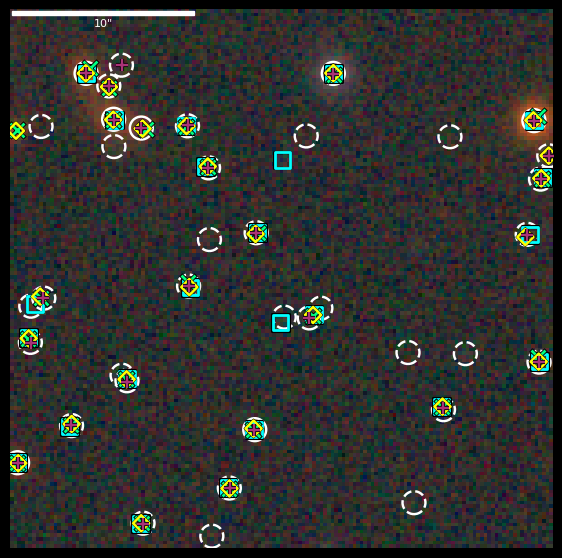

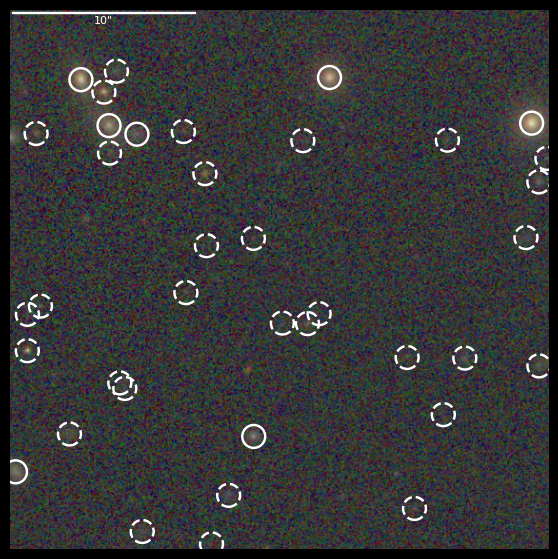

In [41]:
# Final pair for the paper: LSST-frame + Roman-frame figures, saved
# separately (to be combined side by side in LaTeX). LSST panel: gold+
# buffer (truth_mode='split' -- gold solid, buffer dashed) with every
# detection shown (det_gold_only=False), no legend of its own
# (show_legend=False) -- using the shared standalone legend below instead.
# Roman panel: truths ONLY (show_dets=()), also no legend -- it's a
# companion view of the same truth population, not a second detection
# comparison. Both black background.
#
# formats=('png',) is the default (fast preview); pass formats=('png',
# 'pdf') on any of the three calls below to also get a vector PDF at the
# same path (out_path's own extension doesn't matter, see
# _savefig_formats) -- e.g. for the final paper figures once you're happy
# with the PNG previews:
#   plot_scene_dets(..., formats=('png', 'pdf'))
# Note save_standalone_legend's PDF (if requested) won't get the same
# tight pixel-crop as its PNG -- see that function's docstring.
plot_scene_dets(chosen_fn, catalogs, out_dir / f'scene_dets_c110_53.71_-41.5.png',
                 truth_mode='split', det_gold_only=False, show_legend=False, black_bg=True,
                 formats=('png','pdf'))

plot_scene_roman(chosen_fn, catalogs, out_dir / f'scene_roman_c110_53.71_-41.5.png',
                  truth_mode='split', show_dets=(), show_legend=False, black_bg=True,
                  formats=('png','pdf'))

save_standalone_legend(out_dir / 'scene_legend.png', truth_mode='split', black_bg=True)

In [42]:
save_standalone_legend(out_dir / 'scene_legend.png', truth_mode='split', black_bg=True, formats=('png','pdf'))

[PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/scene_legend.png'),
 PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/scene_legend.pdf')]

## LaTeX

In [43]:
# FIXED -- reflects the actual selection algorithm implemented above
# (truth_table + the n_truth<=40 / LSST-out-match / ordering filters);
# pulled straight from the notebook's own variables/constants, so this
# stays correct automatically if those change. No hand-editing needed here.
match_criterion = (
    r'\#matches$_{\rm LSST}$ $\leq$ \#matches$_{\rm Rubin30k}$ $<$ '
    r'\#matches$_{\rm RubinUps}$ $<$ \#matches$_{\rm Combined}$'
)
# Replaces the earlier n_gained/n_blend_gained-ranked search (removed in
# the notebook cleanup) -- the current method is simpler: cap scene
# complexity up front (n_truth<=40, for legibility -- seeing ~55 objects/
# scene on average made every early render too cluttered to read), drop
# scenes where the classical LSST Pipelines baseline already beats every
# DeepDISC variant (not informative for a joint-survey-benefit figure),
# then require the per-scene match counts to improve monotonically
# (match_criterion above), and pick by eye from the LSST|Roman thumbnail
# previews of the scenes with the fewest remaining truth objects.
selection_desc = (
    r"restricted to scenes with at most 40 truth objects (so the figure "
    r"stays legible) where the LSST Pipelines baseline did not already "
    r"match more truth objects than every DeepDISC variant, then, among "
    r"scenes satisfying the per-scene match-count criterion above, this "
    r"scene was chosen by eye from those with the fewest truth objects"
)

# RESOLVED -- matches the notebook's actual locked-in defaults
# (DEFAULT_TRUTH_MODE / DEFAULT_DET_GOLD_ONLY, both used explicitly in the
# final-pair render cell), so each is a single fixed string rather than a
# live options list to pick from. If a specific render ever deviates from
# these defaults, update the matching line here to match.
candidate_pool_desc = rf"the gold+buffer sample (mag$_i$<{mag_limit_val:.2f})"
truth_display_desc = (
    r"gold truth as solid circles and buffer truth (mag$_i \geq$"
    rf"{GOLD_CUT:.2f}) as dashed circles (truth_mode='split')"
)
det_display_desc = "all detections in the loaded catalog (det_gold_only=False)"

selection_note = (
    rf"Among test-set scenes at LL={chosen_ll}\arcsec drawn from "
    rf"{candidate_pool_desc}, {selection_desc}. "
    rf"Truth objects are shown as {truth_display_desc}. "
    rf"Detections shown are {det_display_desc}."
)

print('--- Resolved defaults used in the caption below ---')
print('candidate pool:', candidate_pool_desc)
print('truth display: ', truth_display_desc)
print('det display:   ', det_display_desc)
print()
print('(figures/scene_dets_final.png, figures/scene_roman_final.png, and')
print(' figures/scene_legend.png are the three files the combined figure')
print(' below includes -- see the final-pair render cell above. Pass')
print(' formats=(\'png\', \'pdf\') there for vector versions of the same three.)')
print()

# ONE combined figure* (not two separate ones) since the LSST/Roman panels
# now share a single legend instead of each carrying its own -- see the
# final-pair render cell's comment. Tune the two \subfloat widths /
# \includegraphics width for the legend once you see how it lays out;
# these are starting values, not measured against the actual page.
main_fig = rf"""\begin{{figure*}}
  \centering
  \subfloat{{\includegraphics[width=0.45\textwidth]{{figures/scene_dets_final.png}}}}
  \hfill
  \subfloat{{\includegraphics[width=0.45\textwidth]{{figures/scene_roman_final.png}}}}\\[1ex]
  \includegraphics[width=0.5\textwidth]{{figures/scene_legend.png}}
  \caption{{Scene-level detection comparison on a representative test set LSST cutout (left), shown as a Lupton asinh-stretched RGB composite of the $i/r/g$ bands with the pixel scale indicated by the scalebar, alongside the Roman view of the same scene (right, Lupton asinh-stretched $H158/J129/Y106$ composite, illustrating the finer pixel scale available to the joint-survey model). Truth objects are marked in both panels; the left panel additionally shows detections from the LSST Pipelines, the Rubin-only DeepDISC baseline, the Rubin-upsampled model, and the joint-survey Rubin+Roman model, with the shared legend below. {selection_note}}}
  \label{{fig:scene}}
\end{{figure*}}"""

print(main_fig)

--- Resolved defaults used in the caption below ---
candidate pool: the gold+buffer sample (mag$_i$<27.30)
truth display:  gold truth as solid circles and buffer truth (mag$_i \geq$25.30) as dashed circles (truth_mode='split')
det display:    all detections in the loaded catalog (det_gold_only=False)

(figures/scene_dets_final.png, figures/scene_roman_final.png, and
 figures/scene_legend.png are the three files the combined figure
 below includes -- see the final-pair render cell above. Pass
 formats=('png', 'pdf') there for vector versions of the same three.)

\begin{figure*}
  \centering
  \subfloat{\includegraphics[width=0.45\textwidth]{figures/scene_dets_final.png}}
  \hfill
  \subfloat{\includegraphics[width=0.45\textwidth]{figures/scene_roman_final.png}}\\[1ex]
  \includegraphics[width=0.5\textwidth]{figures/scene_legend.png}
  \caption{Scene-level detection comparison on a representative test set LSST cutout (left), shown as a Lupton asinh-stretched RGB composite of the $i/r/g$ 